In [1]:
#pip install tensorflow

In [2]:
import os
import numpy as np
import tensorflow as tf
import pandas as pd
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

In [14]:
tf.keras.utils.set_random_seed(16)

In [3]:
#import the data from csv file
csv_filename= "../datacleaning-pipeline/pnw_model_dataset.csv.gz"
df = pd.read_csv(csv_filename, dtype={'gauge_id':str}, parse_dates=['date'])

In [4]:
#seelction of the variables
input_columns = ['prcp_z', 'tmax_z', 'srad_z','vp_z', 'dayl_z', 'drainage_area_km2_z', 'elevation_m_z', 'slope_m_per_km_z','frac_forest_z', 'mean_precip_mm_day_z', 'mean_pet_mm_day_z']
target_column = ['log_runoff']

In [6]:
#Training vs Testing Period and Data
training_df=df[df['split'] =='train']
testing_df=df[df['split']=='test']

X_training = training_df[input_columns].values
X_testing = testing_df[input_columns].values

y_training =training_df[target_column].values.reshape(-1,1)
y_testing =testing_df[target_column].values.reshape(-1,1)

print(f'Training array of size : {X_training.shape}')

Training array of size : (149732, 11)


In [7]:
#Modeling

model = models.Sequential([
    layers.Input(shape=(X_training.shape[1],)),
    layers.Dense(50, activation ='relu'),
    layers.Dense(50, activation='relu'),
    layers.Dense(25,activation='relu'),
    layers.Dense(1, activation='linear')])

In [8]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 50)                  │             600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 50)                  │           2,550 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 25)                  │           1,275 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              26 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,451 (17.39 KB)

 Trainable params: 4,451 (17.39 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
print('\n Beginning training... \n')
model.fit(X_training, y_training, epochs=10, batch_size=50, verbose=1)
print('\n Training complete!\n')


 Beginning training... 

Epoch 1/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - loss: 0.2095 - mae: 0.3318
Epoch 2/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.1616 - mae: 0.2910
Epoch 3/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 0.1535 - mae: 0.2821
Epoch 4/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.1487 - mae: 0.2766
Epoch 5/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.1453 - mae: 0.2730
Epoch 6/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 0.1421 - mae: 0.2692
Epoch 7/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 0.1395 - mae: 0.2665
Epoch 8/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - loss: 0.1373 - mae: 0.2639
Epoch 9/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.1357 - mae: 0.2620
Epoch 10/10
2995/2995 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.1343 - mae: 0.2607

 Training complete!



In [10]:
test_loss, test_mae = model.evaluate(X_testing, y_testing, verbose=0)
raw_mae= np.expm1(test_mae)
y_predict_log =model.predict(X_testing)
y_true_raw= np.expm1(y_testing)
y_predict_raw= np.expm1(y_predict_log)

y_true = y_true_raw.flatten()
y_predict = y_predict_raw.flatten()

print(f'Test MSE (Log Loss):{test_loss:.4f}')
print(f'Test MAE (Log MAE):{test_mae:.4f}')
print(f'Test MAE (Raw mm/day):{raw_mae:.4f}')

2809/2809 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
Test MSE (Log Loss):0.1531
Test MAE (Log MAE):0.2788
Test MAE (Raw mm/day):0.3215


In [11]:
nse_score = r2_score(np.expm1(y_testing), np.expm1(model.predict(X_testing)))
rmse_score =np.sqrt(mean_squared_error(y_true,y_predict))
print(f'This model has a NSE score of {nse_score:.4f}')
print(f'This model has a RMSE Score of {rmse_score:.4f}')

2809/2809 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
This model has a NSE score of 0.6289
This model has a RMSE Score of 4.0007


This NSE seems way too high for a this type of not "optimized" hydrological model. I therefore ran a individual test to determine the actual NSE. Please see my report. 

In [12]:
test_df=df[df['split']=='test'].copy()
test_df['pred_raw']=y_predict_raw
test_df['true_raw']=y_true_raw

nse_individual =[]

for gauge, group in test_df.groupby('gauge_id'):
    basin_nse = r2_score(group['true_raw'],group['pred_raw'])
    nse_individual.append(basin_nse)

print(f'Mean per basin NSE {np.mean(nse_individual):4f}')

Mean per basin NSE 0.543226


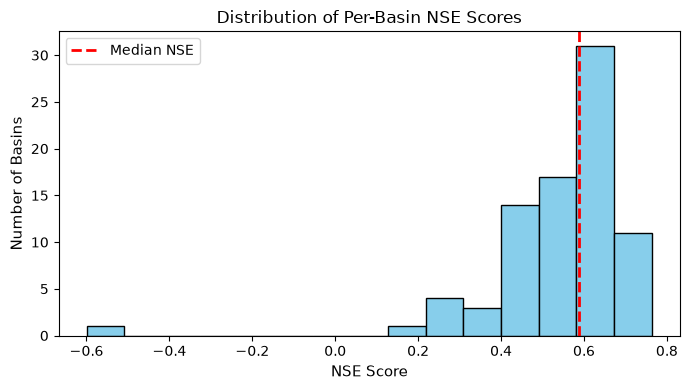

In [15]:
import matplotlib.pyplot as plt


plt.figure(figsize=(7, 4))

plt.hist(nse_individual, bins=15, edgecolor='black', color='skyblue')


median_nse = np.median(nse_individual)
plt.axvline(median_nse, color='red', linestyle='--', linewidth=2, label=f'Median NSE')


plt.xlabel('NSE Score', fontsize=11)
plt.ylabel('Number of Basins', fontsize=11)
plt.title('Distribution of Per-Basin NSE Scores', fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()